In [1]:
print("Hello! Welcome to my project")
print("Student Performance Prediction System")
print("Project started successfully!")

Hello! Welcome to my project
Student Performance Prediction System
Project started successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
url = "https://raw.githubusercontent.com/MakroMB/student-performance-analysis/main/data/student-mat.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")

print(df.head())

Dataset loaded successfully!
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape:
(395, 33)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-

In [5]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values in Each Column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
0


In [6]:
print("Duplicate records:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("\nDataset after removing duplicates:")
print(df.shape)

Duplicate records:
0

Dataset after removing duplicates:
(395, 33)


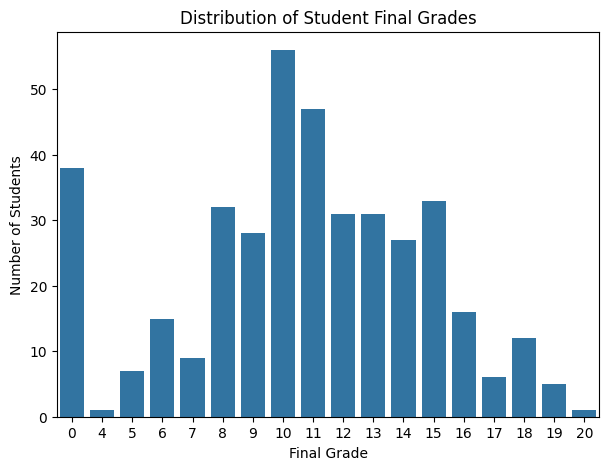

In [7]:
plt.figure(figsize=(7,5))

sns.countplot(x="G3", data=df)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

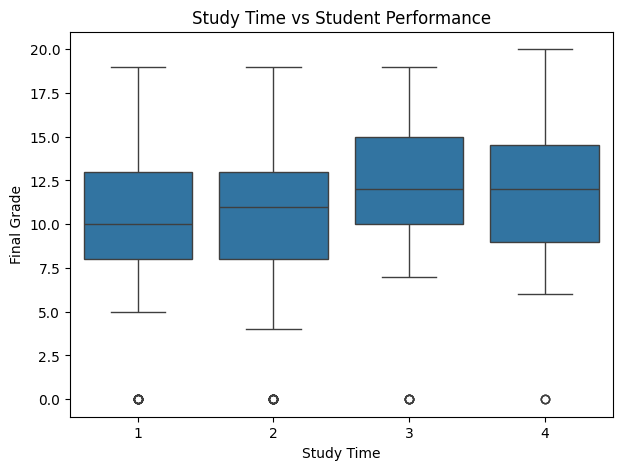

In [8]:
plt.figure(figsize=(7,5))

sns.boxplot(x="studytime", y="G3", data=df)

plt.title("Study Time vs Student Performance")
plt.xlabel("Study Time")
plt.ylabel("Final Grade")

plt.show()

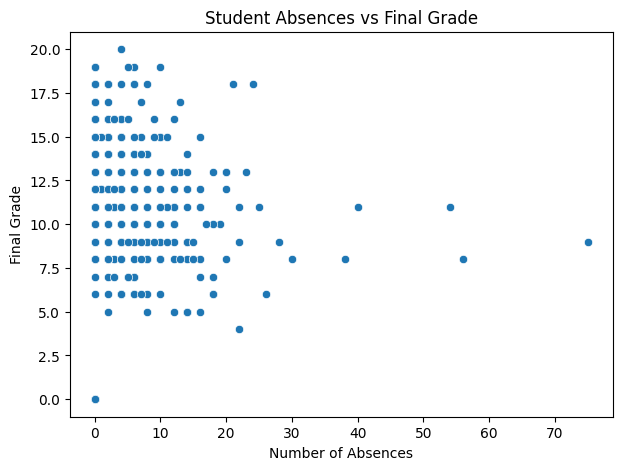

In [9]:
plt.figure(figsize=(7,5))

sns.scatterplot(x="absences", y="G3", data=df)

plt.title("Student Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.show()

In [10]:
df["Performance"] = np.where(
    df["G3"] >= 10, 1, 0
)

print("Performance categories created!")

print(df[["G3", "Performance"]].head(10))

print("\nCategory Count:")
print(df["Performance"].value_counts())

Performance categories created!
   G3  Performance
0   6            0
1   6            0
2  10            1
3  15            1
4  10            1
5  15            1
6  11            1
7   6            0
8  19            1
9  15            1

Category Count:
Performance
1    265
0    130
Name: count, dtype: int64


In [11]:
features = [
    "age",
    "Medu",
    "Fedu",
    "studytime",
    "failures",
    "absences",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health"
]

X = df[features]
y = df["Performance"]

print("Features selected successfully!")
print(X.head())

print("\nTarget variable:")
print(y.head())

Features selected successfully!
   age  Medu  Fedu  studytime  failures  absences  freetime  goout  Dalc  \
0   18     4     4          2         0         6         3      4     1   
1   17     1     1          2         0         4         3      3     1   
2   15     1     1          2         3        10         3      2     2   
3   15     4     2          3         0         2         2      2     1   
4   16     3     3          2         0         4         3      2     1   

   Walc  health  
0     1       3  
1     1       3  
2     3       3  
3     1       5  
4     2       5  

Target variable:
0    0
1    0
2    1
3    1
4    1
Name: Performance, dtype: int64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (316, 11)
Testing data: (79, 11)


In [14]:
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")

Machine Learning model trained successfully!


In [15]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 65.82278481012658 %

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.27      0.34        26
           1       0.70      0.85      0.77        53

    accuracy                           0.66        79
   macro avg       0.58      0.56      0.56        79
weighted avg       0.63      0.66      0.63        79



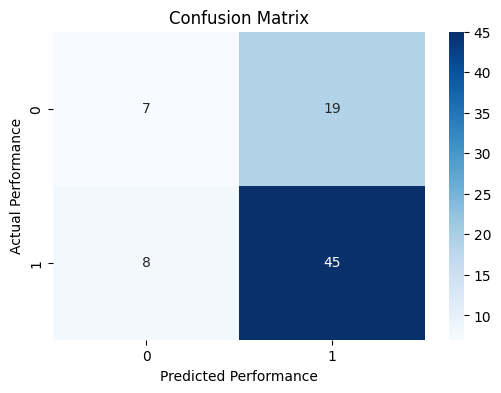

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Performance")
plt.ylabel("Actual Performance")

plt.show()

In [17]:
new_student = pd.DataFrame([{
    "age": 17,
    "Medu": 3,
    "Fedu": 2,
    "studytime": 3,
    "failures": 0,
    "absences": 2,
    "freetime": 3,
    "goout": 2,
    "Dalc": 1,
    "Walc": 2,
    "health": 4
}])

prediction = model.predict(new_student)

if prediction[0] == 1:
    print("Student Performance: GOOD")
else:
    print("Student Performance: NEEDS IMPROVEMENT")

Student Performance: GOOD


In [18]:
balanced_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    )
)

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_test)

print("Improved Model Accuracy:",
      accuracy_score(y_test, balanced_pred) * 100)

print("\nImproved Classification Report:")
print(classification_report(y_test, balanced_pred))

print("\nImproved Confusion Matrix:")
print(confusion_matrix(y_test, balanced_pred))

Improved Model Accuracy: 65.82278481012658

Improved Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.58      0.53        26
           1       0.77      0.70      0.73        53

    accuracy                           0.66        79
   macro avg       0.63      0.64      0.63        79
weighted avg       0.68      0.66      0.66        79


Improved Confusion Matrix:
[[15 11]
 [16 37]]
